<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/04-explainable-ml-with-shap/explainable_ml_with_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Install SHAP

In [ ]:

%pip -q install shap


### Cell 2 - Import libraries

In [ ]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("SHAP version:", shap.__version__)
print("Libraries imported successfully.")


SHAP version: 0.54.1
Libraries imported successfully.


### Cell 3 - Load dataset

In [ ]:

url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/master/"
    "data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)
df.columns = df.columns.str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.drop_duplicates().reset_index(drop=True)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df = df.dropna(subset=["Churn"]).copy()

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Cell 4 - Prepare features and target

In [ ]:

X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].astype(int)

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of features:", X.shape[1])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nTarget distribution:")
display(y.value_counts())


Number of features: 19
Numeric features: 4
Categorical features: 15

Target distribution:


,count
Churn,
0,5174
1,1869


### Cell 5 - Split the dataset

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 5634
Testing samples: 1409


### Cell 6 - Create preprocessing pipeline

In [ ]:

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


### Cell 7 - Train the Gradient Boosting model

In [ ]:

model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Accuracy: 0.8062
Precision: 0.6735
Recall: 0.5241
F1-score: 0.5895
ROC-AUC: 0.8433

Classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



### Cell 8 - Create SHAP explanations

SHAP explains each feature’s contribution to predictions. Positive values increase the churn score, while negative values decrease it. These explain model behavior, not causal effects

In [ ]:

explainer = shap.TreeExplainer(model)

X_explain = X_test_processed.iloc[:200].copy()

shap_values = explainer.shap_values(X_explain)

print("SHAP explanation shape:", np.asarray(shap_values).shape)
print("Number of rows explained:", len(X_explain))


SHAP explanation shape: (200, 45)
Number of rows explained: 200


### Cell 9 — Global feature importance

,Feature,Mean Absolute SHAP
0,cat__Contract_Month-to-month,0.66047
1,num__tenure,0.37365
2,cat__OnlineSecurity_No,0.23256
3,num__MonthlyCharges,0.21363
4,cat__TechSupport_No,0.21237
5,cat__InternetService_Fiber optic,0.19838
6,num__TotalCharges,0.16710
7,cat__PaymentMethod_Electronic check,0.15789
8,cat__Contract_Two year,0.12877
9,cat__MultipleLines_No,0.11483


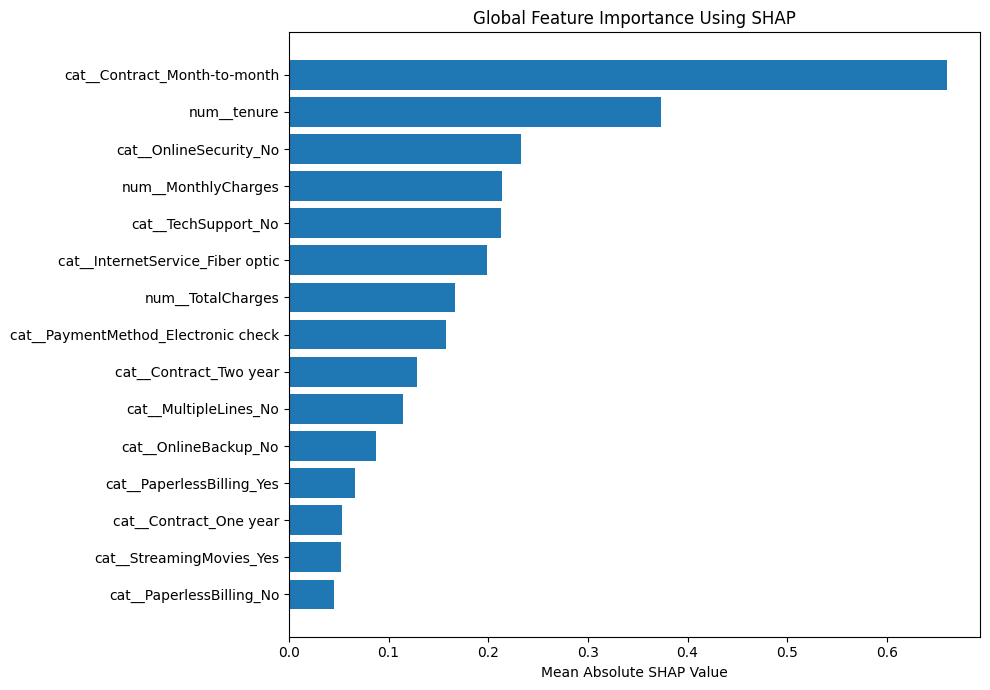

In [ ]:

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    by="Mean Absolute SHAP", ascending=False
).reset_index(drop=True)

display(shap_importance_df.head(15).round(5))

top_features = shap_importance_df.head(15).sort_values(
    by="Mean Absolute SHAP"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Mean Absolute SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global Feature Importance Using SHAP")
plt.tight_layout()
plt.show()


### Cell 10 - SHAP summary / beeswarm plot

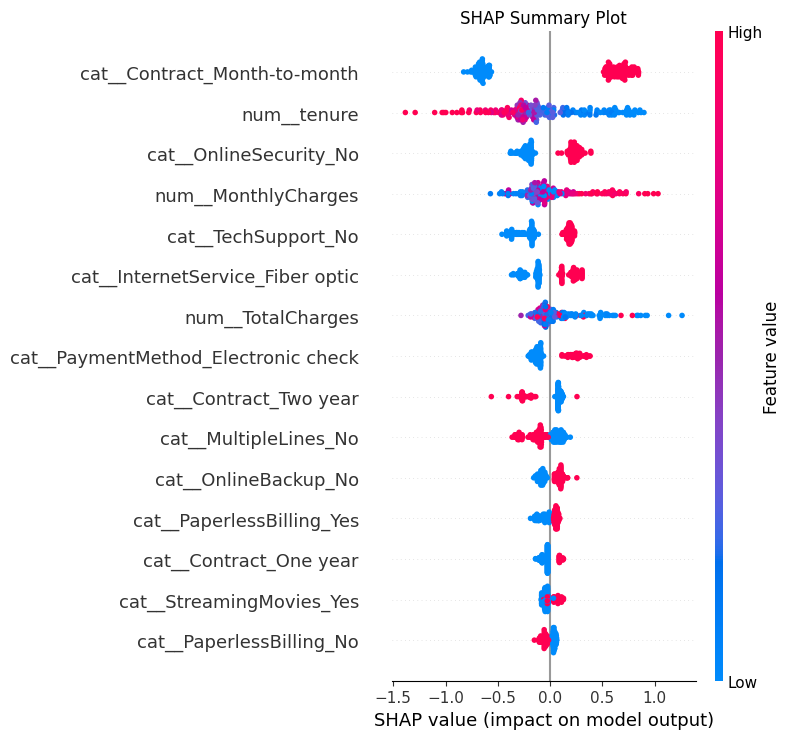

In [ ]:

shap.summary_plot(
    shap_values,
    X_explain,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()


### Cell 11 - Explain one customer prediction

In [ ]:

sample_index = 0

sample = X_explain.iloc[[sample_index]]
sample_probability = model.predict_proba(sample)[0, 1]
sample_prediction = int(model.predict(sample)[0])
sample_actual = int(y_test.loc[sample.index[0]])

print("Predicted churn:", "Yes" if sample_prediction else "No")
print(f"Predicted churn probability: {sample_probability:.2%}")
print("Actual churn:", "Yes" if sample_actual else "No")

display(sample)


Predicted churn: No
Predicted churn probability: 2.48%
Actual churn: No


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
437,0.0,72.0,114.05,8468.2,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


### Cell 12 - SHAP waterfall plot

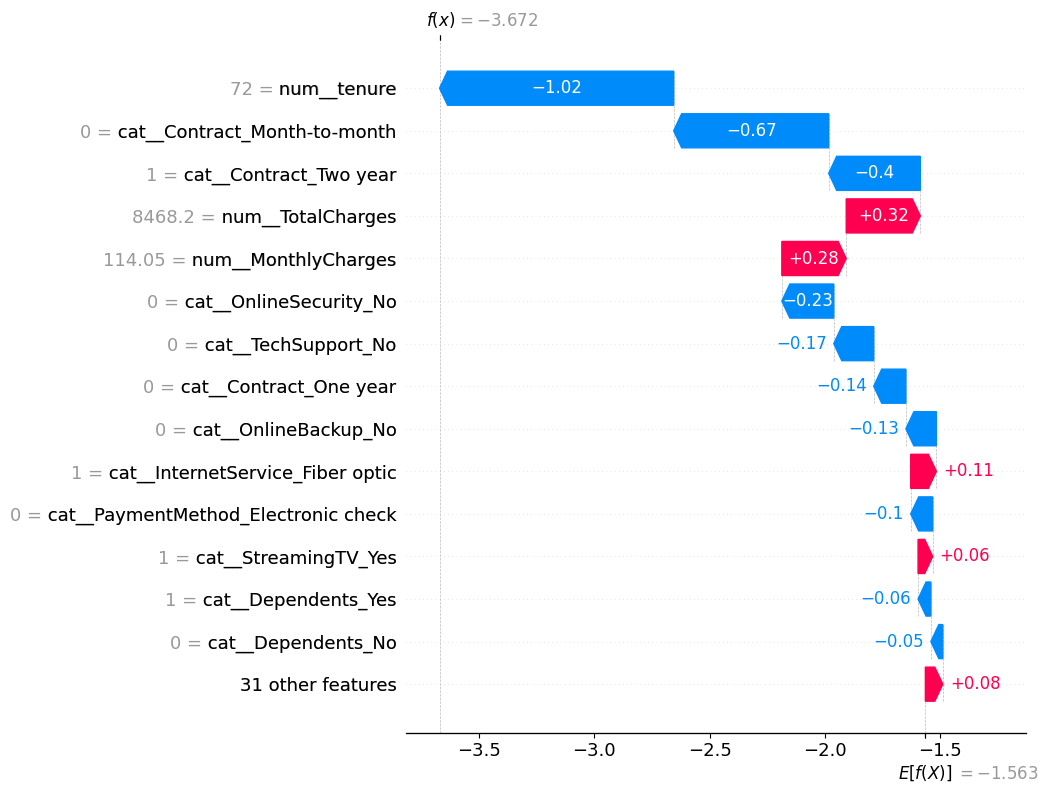

In [ ]:

base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

if isinstance(shap_values, list):
    sample_shap_values = shap_values[1][sample_index]
else:
    sample_shap_values = shap_values[sample_index]

explanation = shap.Explanation(
    values=sample_shap_values,
    base_values=base_value,
    data=X_explain.iloc[sample_index].values,
    feature_names=X_explain.columns.tolist()
)

shap.plots.waterfall(explanation, max_display=15)


### Cell 13 - Save results

In [ ]:

shap_importance_df.to_csv(
    "shap_feature_importance.csv",
    index=False
)

sample_explanation_df = pd.DataFrame({
    "Feature": X_explain.columns,
    "Feature Value": X_explain.iloc[sample_index].values,
    "SHAP Value": sample_shap_values
}).sort_values(
    by="SHAP Value",
    key=lambda values: values.abs(),
    ascending=False
)

sample_explanation_df.to_csv(
    "shap_customer_explanation.csv",
    index=False
)

print("Saved:")
print("- shap_feature_importance.csv")
print("- shap_customer_explanation.csv")


Saved:
- shap_feature_importance.csv
- shap_customer_explanation.csv


### Cell 14 - Generate a summary

In [ ]:

print("EXPLAINABLE MACHINE LEARNING — PROJECT SUMMARY")
print("=" * 50)

print("Dataset rows:", len(df))
print("Features before encoding:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model: Gradient Boosting Classifier")
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nTop 10 global features:")
display(shap_importance_df.head(10).round(5))

print("\nTop customer-level contributors:")
display(sample_explanation_df.head(10).round(5))


EXPLAINABLE MACHINE LEARNING — PROJECT SUMMARY
Dataset rows: 7043
Features before encoding: 19
Training samples: 5634
Testing samples: 1409
Model: Gradient Boosting Classifier
Test ROC-AUC: 0.8433

Top 10 global features:


,Feature,Mean Absolute SHAP
0,cat__Contract_Month-to-month,0.66047
1,num__tenure,0.37365
2,cat__OnlineSecurity_No,0.23256
3,num__MonthlyCharges,0.21363
4,cat__TechSupport_No,0.21237
5,cat__InternetService_Fiber optic,0.19838
6,num__TotalCharges,0.16710
7,cat__PaymentMethod_Electronic check,0.15789
8,cat__Contract_Two year,0.12877
9,cat__MultipleLines_No,0.11483



Top customer-level contributors:


,Feature,Feature Value,SHAP Value
1,num__tenure,72.00,-1.01655
36,cat__Contract_Month-to-month,0.00,-0.67312
38,cat__Contract_Two year,1.00,-0.39786
3,num__TotalCharges,8468.20,0.32184
2,num__MonthlyCharges,114.05,0.27949
18,cat__OnlineSecurity_No,0.00,-0.22543
27,cat__TechSupport_No,0.00,-0.17354
37,cat__Contract_One year,0.00,-0.13959
21,cat__OnlineBackup_No,0.00,-0.13251
16,cat__InternetService_Fiber optic,1.00,0.11151


### Cell 15 - Download the results

In [ ]:

from google.colab import files

files.download("shap_feature_importance.csv")
files.download("shap_customer_explanation.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>